## Zbiór danych mushroom

In [4]:
import matplotlib.pyplot as plt

from id4 import Node, buildTree, predict
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import math

In [61]:
data = pd.read_csv("./mushrooms.csv")
train_data, test_data = train_test_split(data, test_size=0.3, random_state=0)
X_train = train_data.drop(columns=["class"], axis=1)
Y_train = train_data["class"]
X_test = test_data.drop(columns=["class"], axis=1)
Y_test = test_data["class"]

Node.all_classes = list(Y_train.unique())
Node.all_attributes = list(X_train.keys())
for k in X_train.keys():
    Node.possible_values_attribute[k] = list(X_train[k].unique())


# Rozkład klas

<AxesSubplot: xlabel='class', ylabel='Count'>

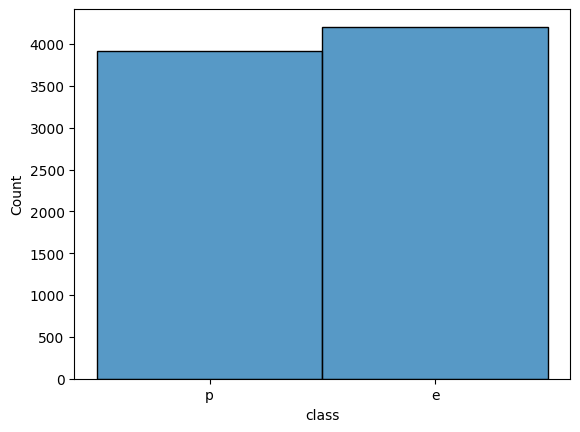

In [44]:
import seaborn
seaborn.histplot(data["class"])

## Uczenie całym zbiorem

In [9]:
tree_batch = Node(Node.all_attributes)

# train tree by batch
tree_batch = buildTree(train_data, tree_batch)
y_pred = predict(test_data, tree_batch)

## Dokładność 100%

W tym konkretnym zbiorze danych jest to osiągalne. Dodatkowy sanity-check: drzewo decyzyjne z funkcji bibliotecznej również osiągnęło ten wynik.

In [10]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test, y_pred)

1.0

## Uczenie pojedynczymi próbkami

In [45]:
batches = [1000, 500, 200, 100, 50, 25, 10, 5, 1]
scores = {batch: [] for batch in batches}
# train tree by single instances
for batch_size in batches:
    tree_samples = Node(Node.all_attributes)
    print("Batch size: ",batch_size)
    for i in tqdm(range(math.ceil(len(train_data) / batch_size))):
        rows = train_data[i*batch_size:i*batch_size+batch_size]
        #r_df = pd.DataFrame(rows.to_frame().T)
        tree_samples = buildTree(rows, tree_samples)
        y_pred = predict(test_data, tree_samples)
        scores[batch_size].append(accuracy_score(Y_test, y_pred))

Batch size:  1000


100%|██████████| 7/7 [00:20<00:00,  2.86s/it]


Batch size:  500


100%|██████████| 13/13 [00:20<00:00,  1.55s/it]


Batch size:  200


100%|██████████| 33/33 [00:21<00:00,  1.56it/s]


... (8 outputs left out)

Batch size:  5


100%|██████████| 1300/1300 [01:37<00:00, 13.27it/s]


Batch size:  1


100%|██████████| 6499/6499 [06:35<00:00, 16.45it/s]


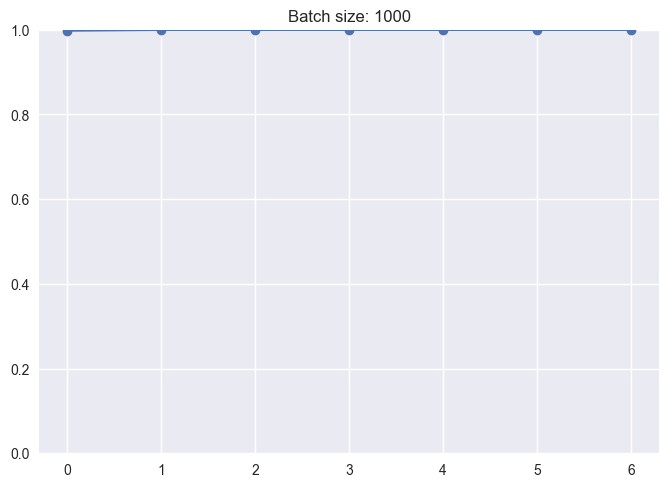

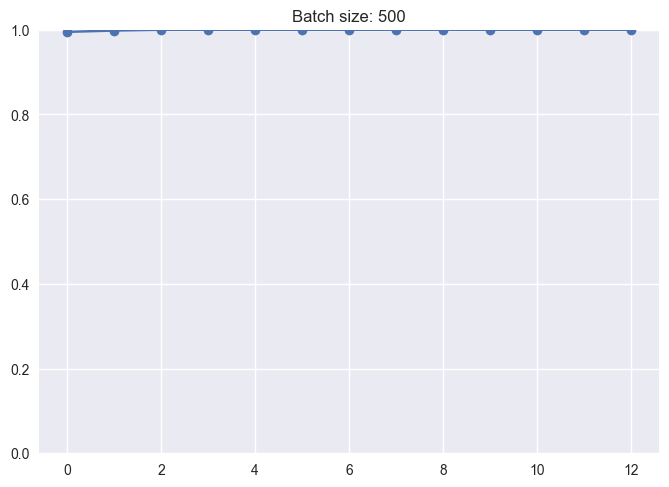

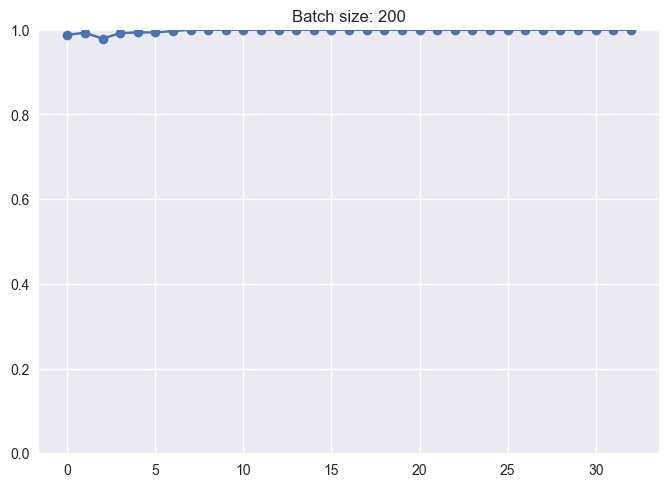

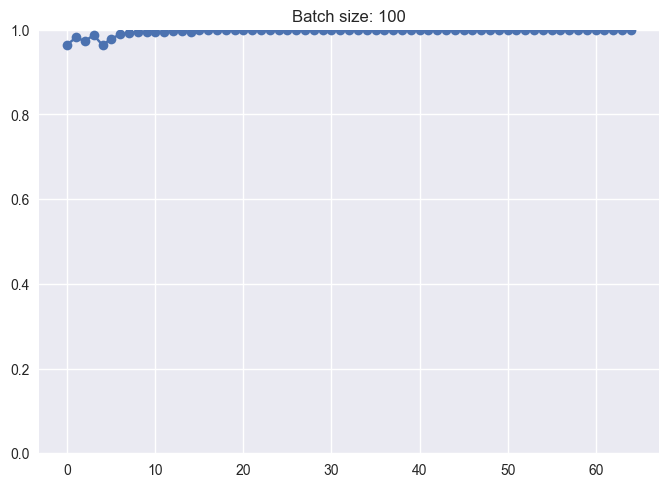

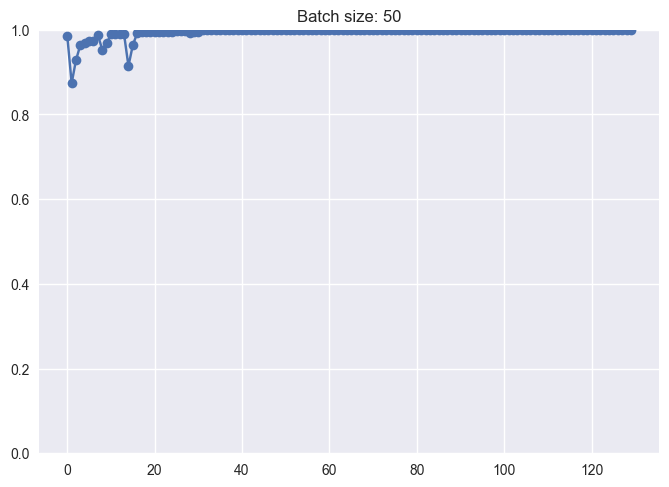

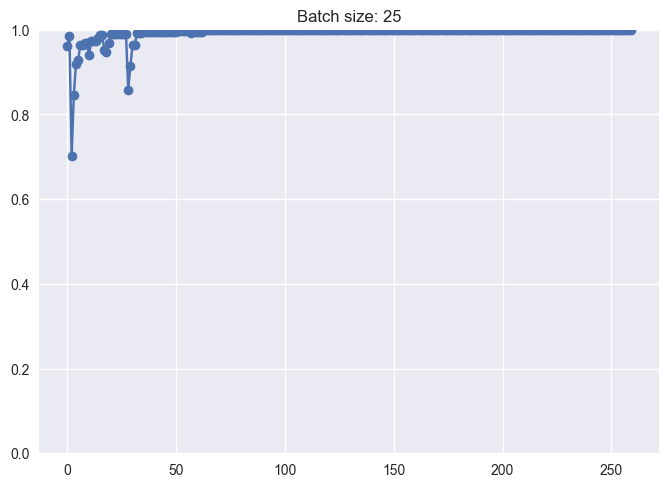

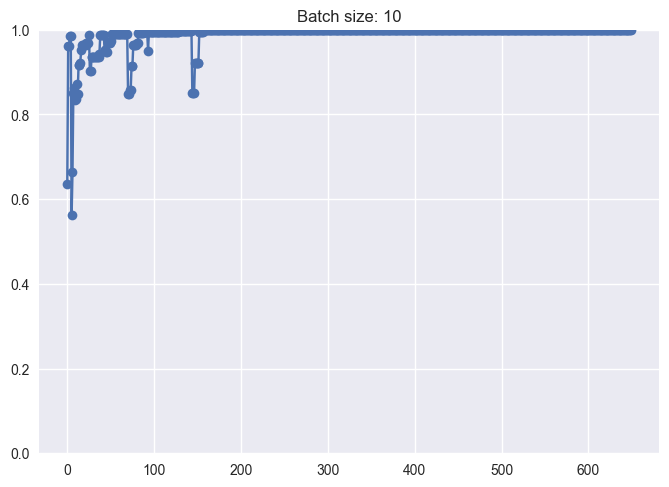

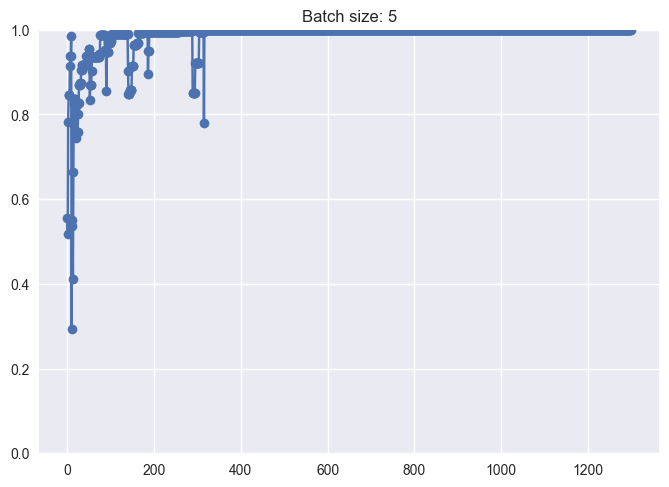

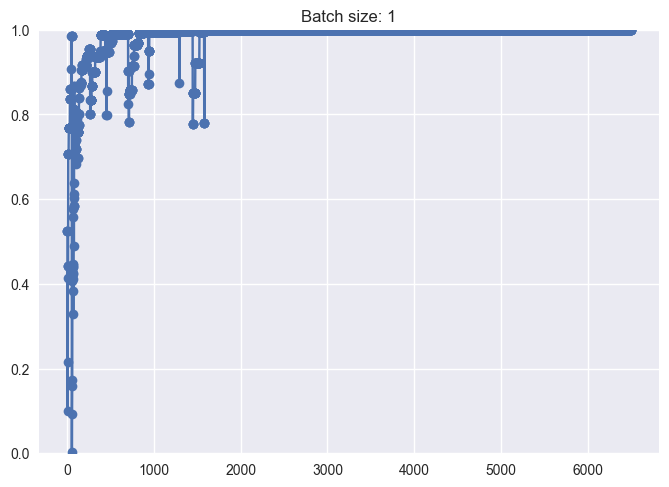

In [51]:
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
for batch, scr in scores.items():
    plt.plot(scr, 'o-')
    plt.ylim(0, 1)
    plt.title(f"Batch size: {batch}")
    plt.show()

## Drzewo decyzyjne z scikit-learn

In [62]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(random_state=0)

X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)
Y_train_encoded = pd.get_dummies(Y_train)
Y_test_encoded = pd.get_dummies(Y_test)
dtc.fit(X_train_encoded, Y_train_encoded)

DecisionTreeClassifier(random_state=0)

In [65]:
y_pred = dtc.predict(X_test_encoded)
accuracy_score(Y_test_encoded, y_pred)

1.0

## Zbiór danych tic-tac-toe

In [66]:
data = pd.read_csv("./tic-tac-toe.data")
train_data, test_data = train_test_split(data, test_size=0.2, random_state=0)
X_train = train_data.drop(columns=["class"], axis=1)
Y_train = train_data["class"]
X_test = test_data.drop(columns=["class"], axis=1)
Y_test = test_data["class"]

Node.all_classes = list(Y_train.unique())
Node.all_attributes = list(X_train.keys())
for k in X_train.keys():
    Node.possible_values_attribute[k] = list(X_train[k].unique())

## Rozkład klas

<AxesSubplot: xlabel='class', ylabel='Count'>

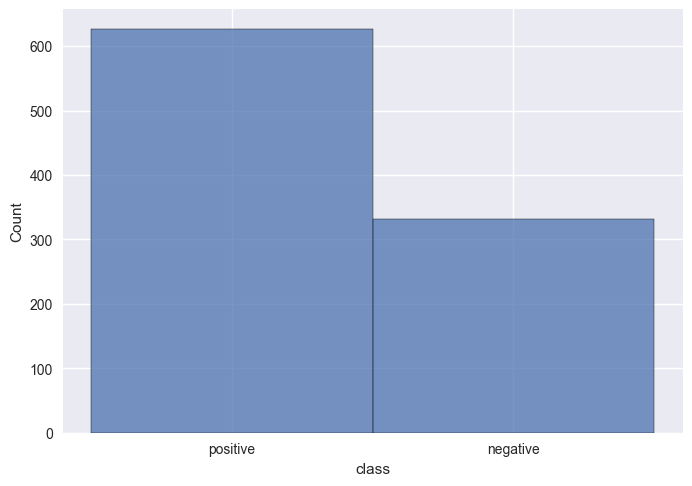

In [67]:
seaborn.histplot(data["class"])

# Uczenie całym zbiorem naraz - 87%

In [68]:
tree_batch = Node(Node.all_attributes)

# train tree by batch
tree_batch = buildTree(train_data, tree_batch)
y_pred = predict(test_data, tree_batch)
accuracy_score(Y_test, y_pred)

0.8645833333333334

## Uczenie pojedynczymi próbkami - 41%

In [78]:
batches = [1000, 500, 200, 100, 50, 25, 10, 5, 1]
scores = {batch: [] for batch in batches}
dataset_loop_nr = 10 # how many times loop through dataset
# train tree by single instances
for batch_size in batches:
    tree_samples = Node(Node.all_attributes)
    print("Batch size: ",batch_size)
    for _ in range(dataset_loop_nr): # Loop through dataset 10 times
        for i in tqdm(range(math.ceil(len(train_data) / batch_size))):
            rows = train_data[i*batch_size:i*batch_size+batch_size]
            #r_df = pd.DataFrame(rows.to_frame().T)
            tree_samples = buildTree(rows, tree_samples)
            y_pred = predict(test_data, tree_samples)
            scores[batch_size].append(accuracy_score(Y_test, y_pred))

Batch size:  1000


100%|██████████| 1/1 [00:01<00:00,  1.95s/it]


Batch size:  500


100%|██████████| 2/2 [00:01<00:00,  1.02it/s]


Batch size:  200


100%|██████████| 4/4 [00:02<00:00,  1.96it/s]


... (8 outputs left out)

Batch size:  5


100%|██████████| 154/154 [00:03<00:00, 39.80it/s]


Batch size:  1


100%|██████████| 766/766 [00:09<00:00, 83.97it/s]


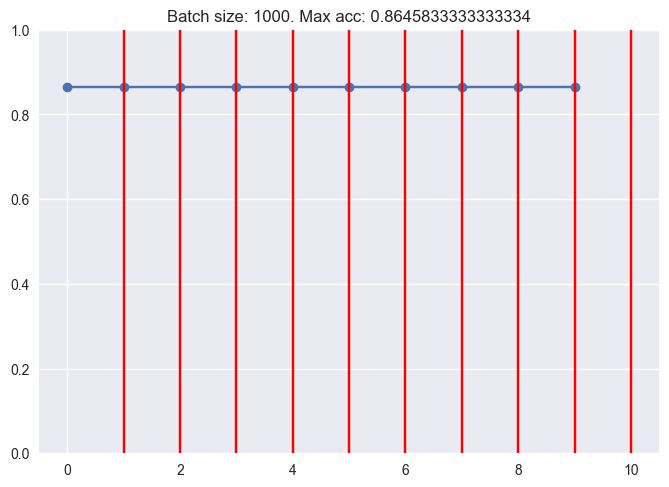

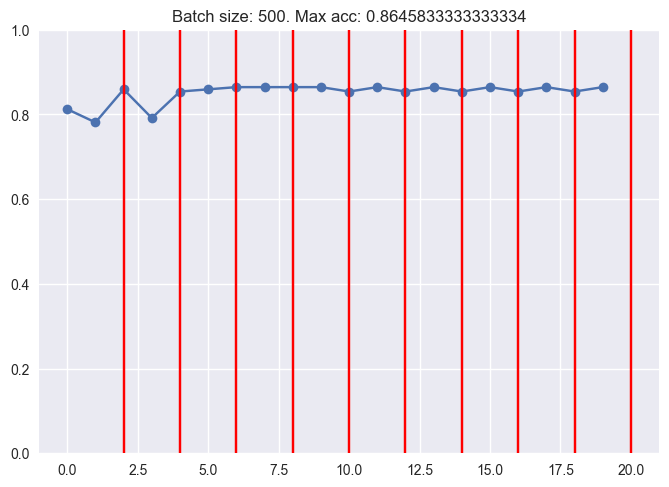

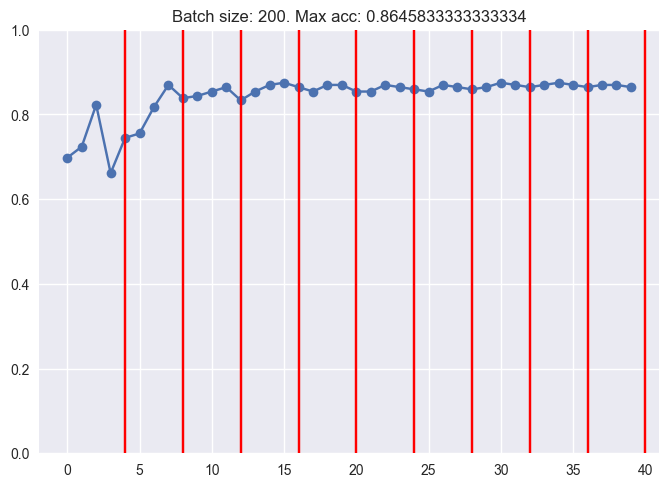

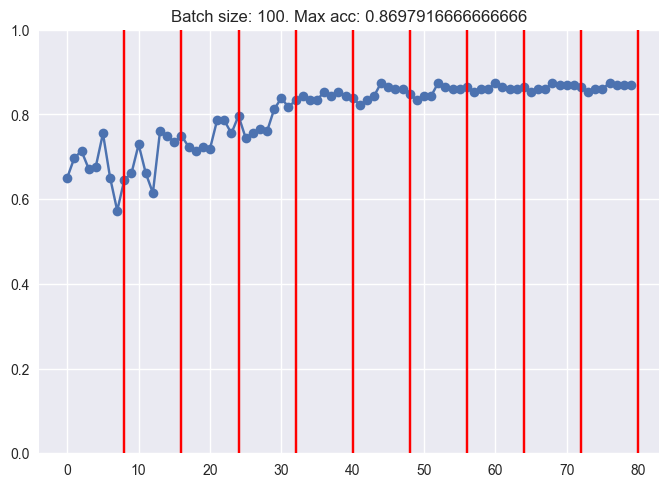

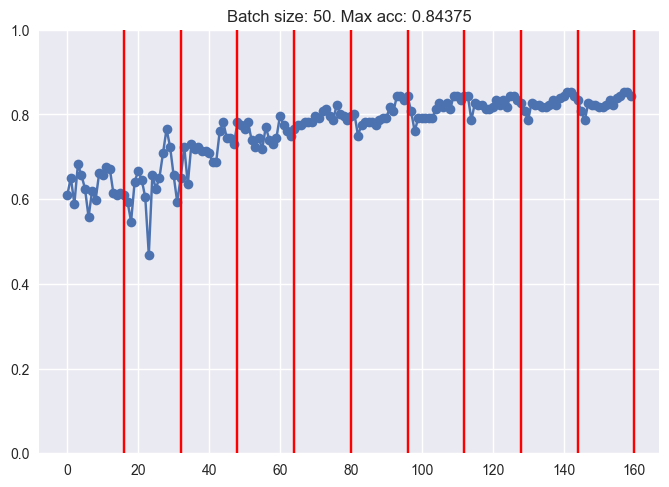

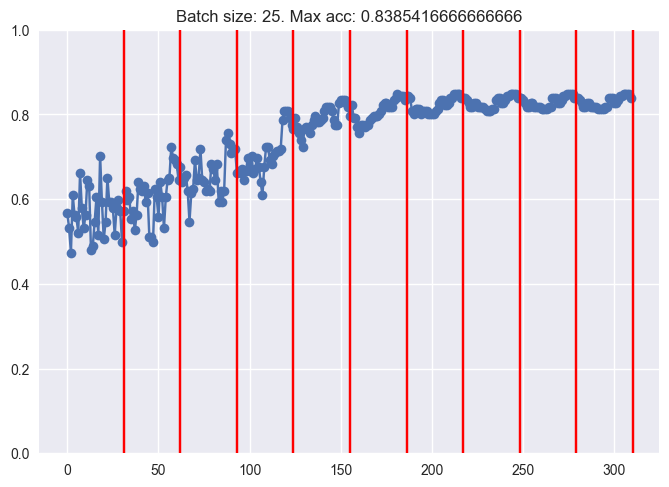

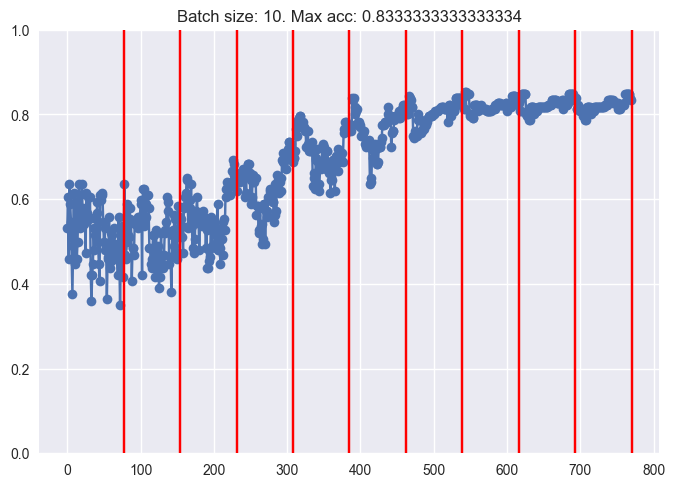

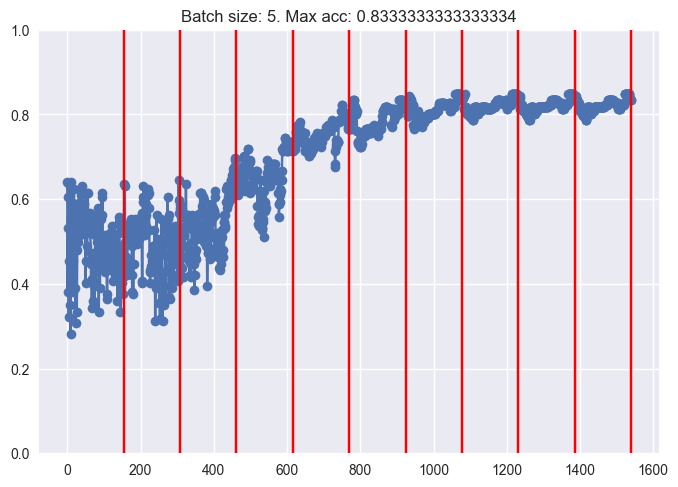

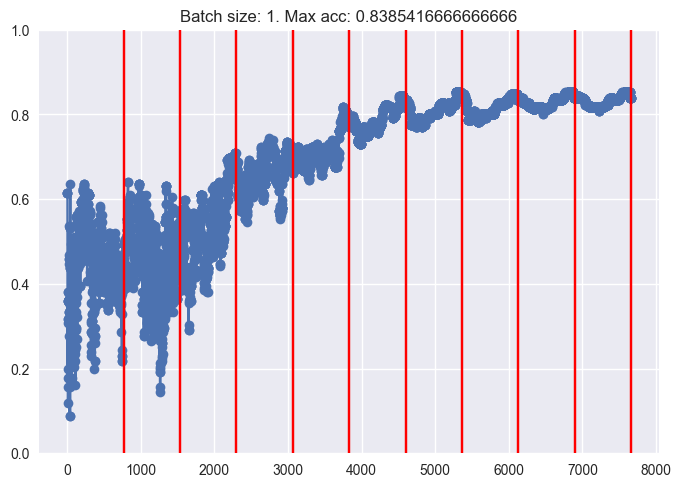

In [84]:
for batch, scr in scores.items():
    plt.plot(scr, 'o-')
    plt.ylim(0, 1)
    for i in range(1, dataset_loop_nr+1):
        plt.axvline(i*math.ceil(len(train_data) / batch), color='red')
    plt.title(f"Batch size: {batch}. Max acc: {scr[-1]}")
    plt.show()

## Drzewo decyzyjne z scikit-learn - 94%

In [77]:
dtc = DecisionTreeClassifier(random_state=0)
X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)
Y_train_encoded = pd.get_dummies(Y_train)
Y_test_encoded = pd.get_dummies(Y_test)
dtc.fit(X_train_encoded, Y_train_encoded)
y_pred = dtc.predict(X_test_encoded)
accuracy_score(Y_test_encoded, y_pred)

0.9427083333333334